    [![preview notebook](https://img.shields.io/static/v1?label=render%20on&logo=github&color=87ce3e&message=GitHub)](https://github.com/open-atmos/PySDM/blob/main/examples/PySDM_examples/featured/Berry_1967/figs_5_8_10.ipynb)
[![launch on mybinder.org](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/open-atmos/PySDM.git/main?urlpath=lab/tree/examples/PySDM_examples/featured/Berry_1967/figs_5_8_10.ipynb)
[![launch on Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/open-atmos/PySDM/blob/main/examples/PySDM_examples/featured/Berry_1967/figs_5_8_10.ipynb)

#### based on Figs. 5, 8, & 10 from Berry 1967 (J. Atmos. Sci. 24)  "_Cloud Droplet Growth by Collection_"   
https://doi.org/10.1175/1520-0469(1967)024%3C0688:CDGBC%3E2.0.CO;2

In [1]:
import os, sys
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'  # PySDM & PyMPDATA don't work with TBB; OpenMP has extra dependencies on macOS
if 'google.colab' in sys.modules:
    !pip --quiet install open-atmos-jupyter-utils
    from open_atmos_jupyter_utils import pip_install_on_colab
    pip_install_on_colab('PySDM-examples', 'PySDM')

In [2]:
from PySDM.physics import si
from PySDM_examples.featured.Berry_1967.spectrum_plotter import SpectrumPlotter
from PySDM_examples.featured.Berry_1967.settings import Settings
from PySDM_examples.featured.Shima_et_al_2009.example import run
from open_atmos_jupyter_utils import show_plot

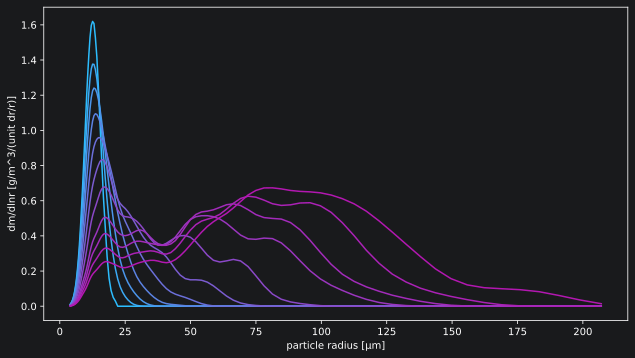

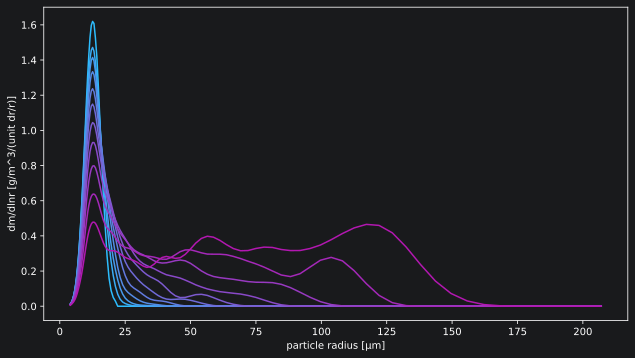

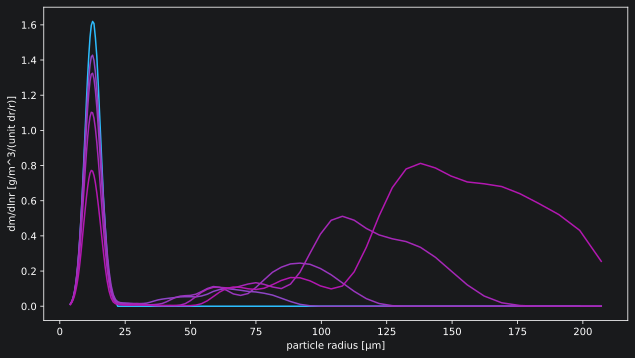

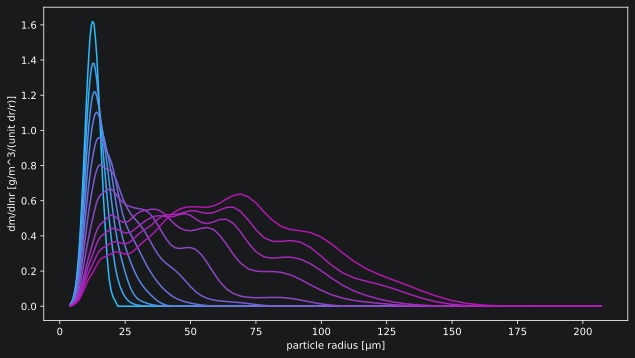

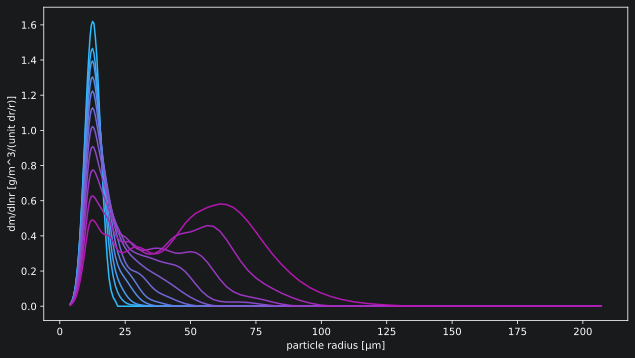

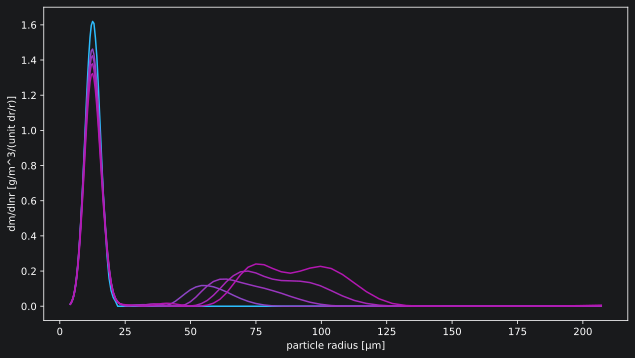

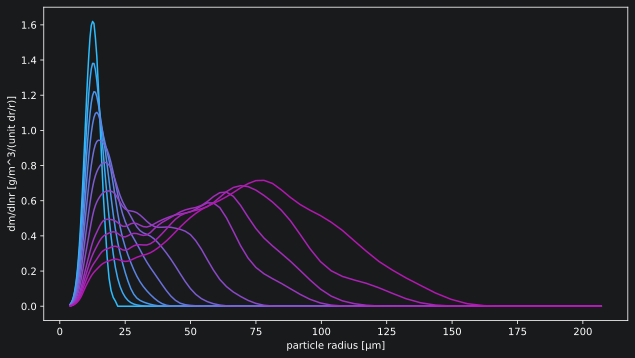

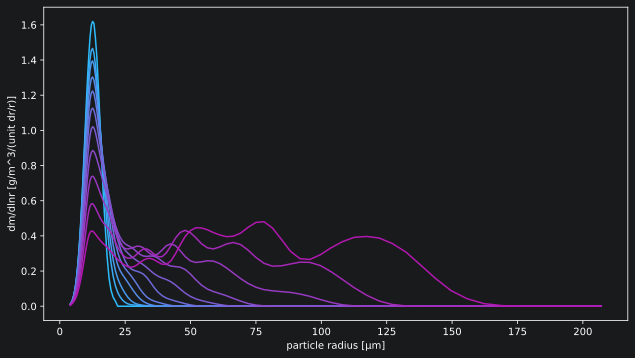

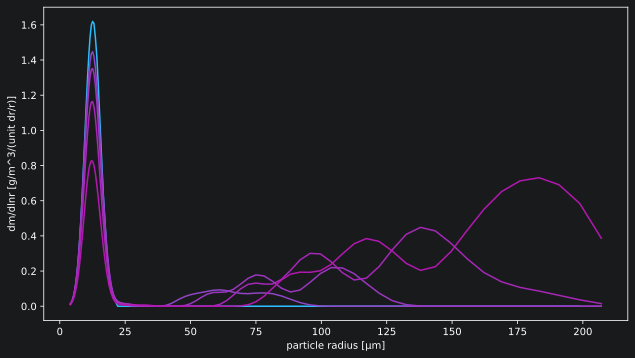

In [5]:
u_term_approxs = ("GunnKinzer1949",)
dts = 1, 10, "adaptive"
setup_prop = {
    "Geometric": (0, 100, 200, 300, 400, 500, 600, 700, 750, 800, 850),
    "electric field 3000V/cm": (0, 100, 200, 300, 400, 500, 600, 700, 800, 900, 1000),
    "hydrodynamic capture": (0, 1600, 1800, 2000, 2200),
}
berry_params = {
    "electric field 3000V/cm": {
        'KERNEL_BERRY_A': 1,
        'KERNEL_BERRY_B': 1,
        'KERNEL_BERRY_D1': -7,
        'KERNEL_BERRY_D2': 1.78,
        'KERNEL_BERRY_E1': -20.5,
        'KERNEL_BERRY_E2': 1.73,
        'KERNEL_BERRY_F1': 0.26,
        'KERNEL_BERRY_F2': 1.47,
        'KERNEL_BERRY_G1': 1,
        'KERNEL_BERRY_G2': 0.82,
        'KERNEL_BERRY_G3': -0.003,
        'KERNEL_BERRY_Mf': 4.4,
        'KERNEL_BERRY_Mg': 8,
        'KERNEL_BERRY_unit': si.um,
    },
    "hydrodynamic capture": {
        'KERNEL_BERRY_A':1,
        'KERNEL_BERRY_B':1,
        'KERNEL_BERRY_D1':-27,
        'KERNEL_BERRY_D2':1.65,
        'KERNEL_BERRY_E1':-58,
        'KERNEL_BERRY_E2':1.9,
        'KERNEL_BERRY_F1':15,
        'KERNEL_BERRY_F2':1.13,
        'KERNEL_BERRY_G1':16.7,
        'KERNEL_BERRY_G2':1,
        'KERNEL_BERRY_G3':0.004,
        'KERNEL_BERRY_Mf':4,
        'KERNEL_BERRY_Mg':8,
        'KERNEL_BERRY_unit':si.um,
    }
}
setups = {}

for u_term_approx in u_term_approxs:
    setups[u_term_approx] = {}
    for dt in dts:
        setups[u_term_approx][dt] = {}
        for kernel_type, steps in setup_prop.items():
            s = Settings(
                terminal_velocity_variant=u_term_approx,
                kernel="Geometric" if kernel_type == "Geometric" else "Berry1967",
                constants={} if kernel_type == "Geometric" else berry_params[kernel_type]
            )
            s.dt = 10 if dt == "adaptive" else dt
            s.adaptive = dt == "adaptive"
            s.steps = steps
            setups[u_term_approx][dt][kernel_type] = s

states = {}
for u_term_approx, setup in setups.items():
    states[u_term_approx] = {}
    for dt in setup:
        states[u_term_approx][dt] = {}
        for kernel in setup[dt]:
            states[u_term_approx][dt][kernel], _ = run(setup[dt][kernel])

for u_term_approx, setup in setups.items():
    for dt in setup:
        for kernel in setup[dt]:
            plotter = SpectrumPlotter(setup[dt][kernel], legend=True)
            for step, vals in states[u_term_approx][dt][kernel].items():
                plotter.plot(vals, step * setup[dt][kernel].dt)
            show_plot(f"{setup[dt][kernel].n_sd}_{u_term_approx}_{dt}_{kernel.replace(' ', '_').replace('/', '_')}")